# Exploratory Data Analysis of Students Performance

## Introduction
This project analyzes the Students Performance dataset using Python, Pandas, NumPy, and Matplotlib. The dataset contains information about students' gender, parental education, lunch type, test preparation course, and scores in mathematics, reading, and writing.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv("StudentsPerformance.csv")

In [5]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [6]:
df.shape

(1000, 8)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [8]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [9]:
df.nunique()

gender                          2
race/ethnicity                  5
parental level of education     6
lunch                           2
test preparation course         2
math score                     81
reading score                  72
writing score                  77
dtype: int64

In [11]:
categorical_columns = df.select_dtypes(include=['str']).columns

for column in categorical_columns:
    print("Column:", column)
    print(df[column].unique())
    print()

Column: gender
<StringArray>
['female', 'male']
Length: 2, dtype: str

Column: race/ethnicity
<StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str

Column: parental level of education
<StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str

Column: lunch
<StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str

Column: test preparation course
<StringArray>
['none', 'completed']
Length: 2, dtype: str



In [12]:
numerical_columns = ['math score', 'reading score', 'writing score']

print("Mean:")
print(df[numerical_columns].mean())

print("\nMedian:")
print(df[numerical_columns].median())

print("\nMode:")
print(df[numerical_columns].mode().iloc[0])

Mean:
math score       66.089
reading score    69.169
writing score    68.054
dtype: float64

Median:
math score       66.0
reading score    70.0
writing score    69.0
dtype: float64

Mode:
math score       65
reading score    72
writing score    74
Name: 0, dtype: int64


In [14]:
df.duplicated().sum()


np.int64(0)

In [15]:
df[df.duplicated()]

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score


In [16]:
numerical_columns = ['math score', 'reading score', 'writing score']

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    
    outliers = df[(df[column] < lower_limit) | (df[column] > upper_limit)]
    
    print("Column:", column)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Number of outliers:", len(outliers))
    print()

Column: math score
Q1: 57.0
Q3: 77.0
IQR: 20.0
Lower limit: 27.0
Upper limit: 107.0
Number of outliers: 8

Column: reading score
Q1: 59.0
Q3: 79.0
IQR: 20.0
Lower limit: 29.0
Upper limit: 109.0
Number of outliers: 6

Column: writing score
Q1: 57.75
Q3: 79.0
IQR: 21.25
Lower limit: 25.875
Upper limit: 110.875
Number of outliers: 5



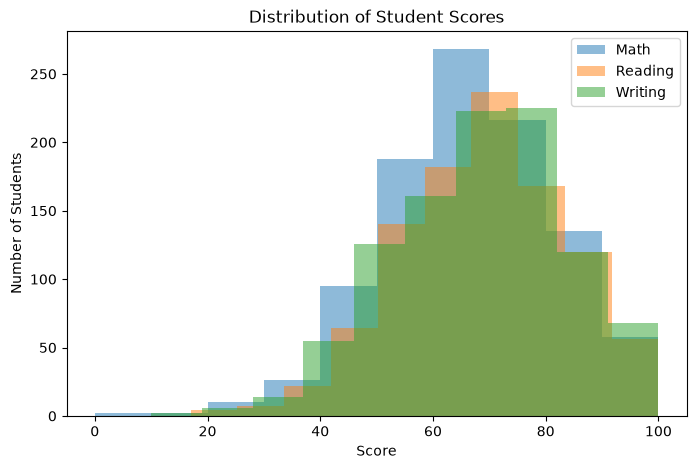

In [17]:
plt.figure(figsize=(8, 5))

plt.hist(df['math score'], bins=10, alpha=0.5, label='Math')
plt.hist(df['reading score'], bins=10, alpha=0.5, label='Reading')
plt.hist(df['writing score'], bins=10, alpha=0.5, label='Writing')

plt.xlabel('Score')
plt.ylabel('Number of Students')
plt.title('Distribution of Student Scores')
plt.legend()
plt.show()

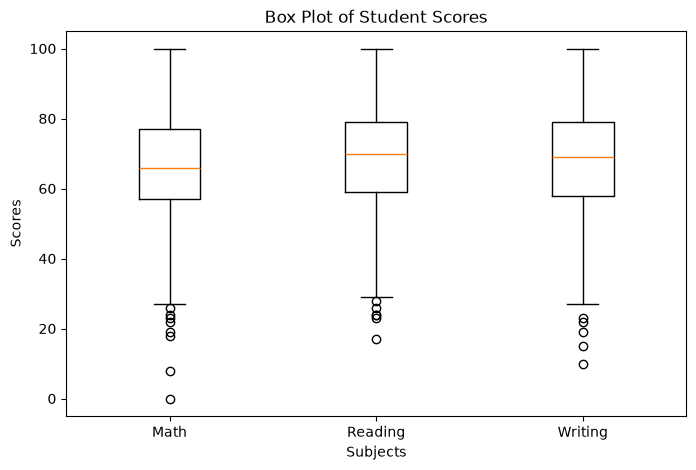

In [19]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [df['math score'], df['reading score'], df['writing score']],
    tick_labels=['Math', 'Reading', 'Writing']
)

plt.title('Box Plot of Student Scores')
plt.xlabel('Subjects')
plt.ylabel('Scores')
plt.show()

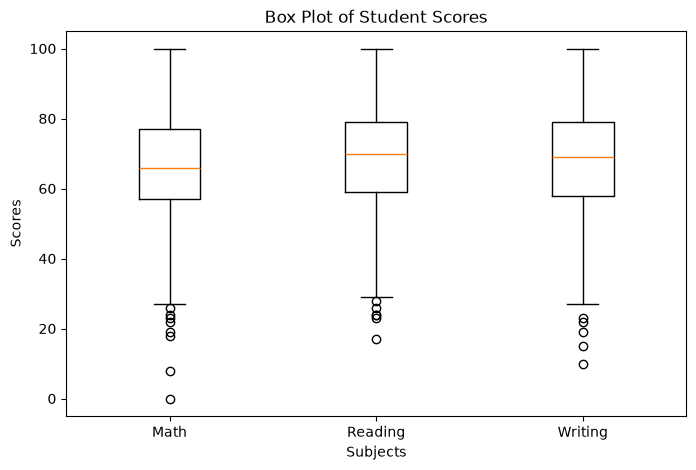

In [21]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [df['math score'], df['reading score'], df['writing score']],
    tick_labels=['Math', 'Reading', 'Writing']
)

plt.title('Box Plot of Student Scores')
plt.xlabel('Subjects')
plt.ylabel('Scores')
plt.show()

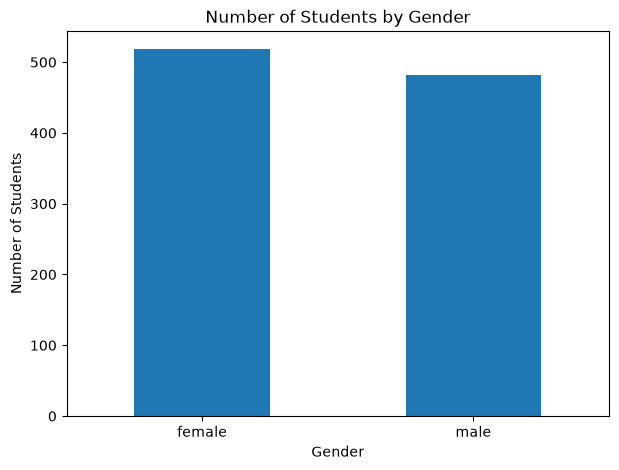

In [23]:
plt.figure(figsize=(7, 5))

df['gender'].value_counts().plot(kind='bar')

plt.title('Number of Students by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Students')
plt.xticks(rotation=0)
plt.show()

In [24]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [25]:
df.groupby('gender')[['math score', 'reading score', 'writing score']].mean()

,math score,reading score,writing score
gender,,,
female,63.633205,72.608108,72.467181
male,68.728216,65.473029,63.311203


In [26]:
df.groupby('test preparation course')[['math score', 'reading score', 'writing score']].mean()

,math score,reading score,writing score
test preparation course,,,
completed,69.695531,73.893855,74.418994
none,64.077882,66.534268,64.504673


In [27]:
correlation = df[['math score', 'reading score', 'writing score']].corr()

print(correlation)

               math score  reading score  writing score
math score       1.000000       0.817580       0.802642
reading score    0.817580       1.000000       0.954598
writing score    0.802642       0.954598       1.000000


## Conclusion

The Students Performance dataset was successfully analyzed using Pandas, NumPy, and Matplotlib. The dataset contains both categorical and numerical data. There were no missing values or duplicate records. Mean, median, and mode were calculated for the numerical columns. Histograms, bar charts, and box plots were used for visualization. Outliers were identified using the IQR method. The analysis also compared average scores based on gender and test preparation course and examined the correlation between the numerical scores.